# Using Predictive Analytics to Identify Engagement Drivers in Instagram Reels
## Notebook 1 of 4: Business Understanding and Data Understanding
**CRISP-DM phases 1 and 2**

### Project roadmap (CRISP-DM)

| CRISP-DM phase | Notebook | What happens there |
|---|---|---|
| 1. Business Understanding | **`01_business_and_data_understanding`** | Objective, analytics goal, success criteria, risks |
| 2. Data Understanding | **`01_business_and_data_understanding`** | Describe, explore, and verify the quality of the raw data |
| 3. Data Preparation | `02_data_preparation` | Select, clean, construct, and format the data |
| 4. Modeling | `03_modeling` | Build, tune, and assess the models |
| 5. Evaluation | `04_evaluation_and_deployment` | Judge results against the business goal and review the process |
| 6. Deployment | `04_evaluation_and_deployment` | Deployment, monitoring, and final review |

CRISP-DM is iterative rather than strictly linear. In this project, lessons from Evaluation led back to Data Understanding (interactions between features) and Data Preparation (interaction features), followed by a second round of Modeling.

---
# Phase 1: Business Understanding

## 1.1 Background and business objective
Audience engagement with short-form Instagram Reels varies widely across videos, even within the same creator's account. Because creators differ in audience size and baseline performance, raw engagement metrics alone do not provide a consistent basis for comparison.

**Business objective:** identify which content characteristics (how a Reel is framed, structured, and delivered) are associated with an above-baseline result in DIY content, so that creators and social media teams can plan content around repeatable patterns instead of guesswork, independent of creator popularity.

## 1.2 Analytics goal
- **Target variable:** `performance_bucket`, a creator-relative label (high-performing vs. baseline). Defining performance relative to each creator's typical output reduces the bias from differences in follower count and reach.
- **Supporting metric:** `engagement_rate` = (likes + comments) / views, used to give context to the performance groups.
- **Task type:** binary classification, plus descriptive analysis of which features are associated with high performance.
- **Candidate techniques:** logistic regression, k-nearest neighbors (k-NN), and a classification tree (Notebook 3).

## 1.3 Success criteria
- **Business:** surface content patterns (hooks, structures, presentation choices) that a team could test in future Reels.
- **Technical:** identify high-performing Reels better than chance on held-out data, judged by **F1 and recall for the high-performing class**. Accuracy alone is not enough because roughly 70% of Reels are baseline, so a model that always predicts "baseline" would already be about 70% accurate while finding no high-performing Reels (confirmed in section 2.4).

## 1.4 Assumptions, constraints, and risks
- **Small sample:** The number of Reels is limited, so some categories have very few examples and validation scores will be noisy.
- **Snapshot data:** Metrics were recorded on `collection_date`, so older Reels have had more time to accumulate views (checked in section 2.4).
- **Missing drivers:** Timing, audience behavior, and algorithmic distribution are not in the dataset and may explain a large share of performance.

## 1.5 Project plan
The roadmap above maps each phase to a notebook. The data file used here is `../Data/raw_data.csv` (one row per Reel).

---
# Phase 2: Data Understanding

## 2.1 Collect initial data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

pd.set_option('display.max_columns', None)

In [2]:
reels_df = pd.read_csv('../Data/raw_data.csv')

print(f"Rows: {reels_df.shape[0]}  |  Columns: {reels_df.shape[1]}")
reels_df.head(10)

Rows: 258  |  Columns: 18


,creator_handle,total_followers,url,date_posted,collection_date,performance_bucket,views_raw,likes_raw,comments_raw,engagement_rate,reel_structure,craft_category,hook_text,hook_category,pov_present,result_shown_first,voice_present,audio_not_required
0,annikamarieee,953K,https://www.instagram.com/reel/DT5we1ZAQS4/,1/24/2026,2/19/2026,baseline,113K,1199,13,NaN,Transformation,Home Decor,FAKE,transformation_tease,Y,Y,Y,Y
1,annikamarieee,953K,https://www.instagram.com/reel/DT3iSi1EyfE/,1/23/2026,2/19/2026,baseline,36.5K,1034,8,NaN,Transformation,Home Decor,how it started vs. how it's going,transformation_tease,Y,N,N,Y
2,annikamarieee,953K,https://www.instagram.com/reel/DTgI-ZoEpwJ/,1/14/2026,2/19/2026,baseline,162K,4619,44,NaN,Process,Home Decor,Can't look at this floor one more day...,transformation_tease,N,N,N,N
3,annikamarieee,953K,https://www.instagram.com/reel/DSVtT-_k5Vm/,12/16/2025,2/19/2026,baseline,285K,8650,54,NaN,Process,Home Decor,NaN,transformation_tease,N,Y,Y,Y
4,annikamarieee,953K,https://www.instagram.com/reel/DSIemD0D07c/,12/11/2025,2/19/2026,baseline,554K,6546,25,NaN,Process,Home Decor,I'm going on a year now without having a dinin...,transformation_tease,N,N,Y,Y
5,annikamarieee,953K,https://www.instagram.com/reel/DMijUhrJqBJ/,7/25/2025,2/19/2026,baseline,615K,28.1K,130,NaN,Process,Home Decor,So I have been really wanting to try out stain...,curiosity_gap,N,N,Y,Y
6,annikamarieee,953K,https://www.instagram.com/reel/DKcmKpDpFLk/,6/3/2025,2/19/2026,baseline,173K,4271,21,NaN,Process,Fine Art / Paint,Comment: We need a Girly Pop Workshop sign,relatable_observation,N,N,N,N
7,annikamarieee,953K,https://www.instagram.com/reel/DJmfm0Xpvcg/,5/13/2025,2/19/2026,high,6.1M,322K,365,NaN,Process,Home Decor,Just throw it away. Me: But it has potential!,transformation_tease,N,N,N,Y
8,annikamarieee,953K,https://www.instagram.com/reel/DJHq-AnvZ7n/,5/1/2025,2/19/2026,high,6.1M,410K,1589,NaN,Process,Plants / Garden,I've been dreaming of a little potting station...,direct_value_delivery,N,Y,Y,Y
9,annikamarieee,953K,https://www.instagram.com/reel/DJUeF9rPTIQ/,5/6/2025,2/19/2026,high,2.2M,185K,530,NaN,Transformation,Home Decor,POV: You made custom shelves for your cat. She...,direct_value_delivery,N,N,N,Y


## 2.2 Describe the data

### Data dictionary (raw file)

| Column | Description | Variable type | Raw format |
|---|---|---|---|
| `creator_handle` | Account name of the creator | Categorical (identifier) | text |
| `total_followers` | Followers of the account | Numerical | text such as `953K` |
| `url` | Link to the Reel (contains the unique Reel ID) | Identifier | text |
| `date_posted` | Date the Reel was published | Date | text, mixed formats |
| `collection_date` | Date performance was recorded | Date | text `m/d/YYYY` |
| `performance_bucket` | Creator-relative performance: high or baseline | Categorical (**target**) | `baseline` / `high` |
| `views_raw`, `likes_raw`, `comments_raw` | Views, likes, comments | Numerical | text such as `113K` |
| `engagement_rate` | Likes and comments relative to views | Numerical | mostly empty (recalculated in Data Preparation) |
| `reel_structure` | How the Reel is organized (list, process, transformation, narrative, showcase) | Categorical | text |
| `craft_category` | Type of craft shown | Categorical | text |
| `hook_text` | Text of the opening hook | Free text | text, missing when the hook is visual |
| `hook_category` | Framing used to attract attention | Categorical | text |
| `pov_present` | Point-of-view framing present | Binary | `Y` / `N` |
| `result_shown_first` | Final result shown in the opening frames | Binary | `Y` / `N` |
| `voice_present` | Spoken audio present | Binary | `Y` / `N` |
| `audio_not_required` | Message understandable without audio | Binary | `Y` / `N` |

Although `performance_bucket` and the delivery variables have only two values, they are treated as categorical (class membership or presence/absence), and no numeric relationship between the values is assumed.

In [3]:
reels_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 258 entries, 0 to 257
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   creator_handle      258 non-null    object 
 1   total_followers     258 non-null    object 
 2   url                 258 non-null    object 
 3   date_posted         258 non-null    object 
 4   collection_date     258 non-null    object 
 5   performance_bucket  258 non-null    object 
 6   views_raw           258 non-null    object 
 7   likes_raw           258 non-null    object 
 8   comments_raw        258 non-null    object 
 9   engagement_rate     0 non-null      float64
 10  reel_structure      258 non-null    object 
 11  craft_category      258 non-null    object 
 12  hook_text           217 non-null    object 
 13  hook_category       258 non-null    object 
 14  pov_present         258 non-null    object 
 15  result_shown_first  258 non-null    object 
 16  voice_pr

## 2.3 Verify data quality

In [4]:
print("Missing values per column:")
print(reels_df.isna().sum(), "\n")

print("Duplicate rows:", reels_df.duplicated().sum())
print("Duplicate URLs:", reels_df['url'].duplicated().sum())

Missing values per column:
creator_handle          0
total_followers         0
url                     0
date_posted             0
collection_date         0
performance_bucket      0
views_raw               0
likes_raw               0
comments_raw            0
engagement_rate       258
reel_structure          0
craft_category          0
hook_text              41
hook_category           0
pov_present             0
result_shown_first      0
voice_present           0
audio_not_required      0
dtype: int64 

Duplicate rows: 0
Duplicate URLs: 12


Although no rows are identical, some URLs appear more than once. Checking which columns differ between the copies:

In [5]:
dup_rows = reels_df[reels_df['url'].duplicated(keep=False)].sort_values('url')

# Which columns differ between the copies of the same URL?
differing = {}
for url, group in dup_rows.groupby('url'):
    for col in reels_df.columns:
        if col != 'url' and group[col].astype(str).nunique() > 1:
            differing[col] = differing.get(col, 0) + 1

print(f"{len(dup_rows)} rows share {dup_rows['url'].nunique()} URLs")
print("Columns that differ between copies (number of URLs affected):", differing)
dup_rows[['url', 'creator_handle', 'date_posted', 'performance_bucket', 'views_raw', 'craft_category']].head(10)

24 rows share 12 URLs
Columns that differ between copies (number of URLs affected): {'performance_bucket': 12}


,url,creator_handle,date_posted,performance_bucket,views_raw,craft_category
93,https://www.instagram.com/reel/DObZ-uZjR53/,aww.sam,9/10/2025,baseline,1.5M,Costume / Wearables
97,https://www.instagram.com/reel/DObZ-uZjR53/,aww.sam,9/10/2025,high,1.5M,Costume / Wearables
105,https://www.instagram.com/reel/DQMKIIBgNH0/,jennifer.maker,10/24/2025,high,126K,Holiday / Seasonal
104,https://www.instagram.com/reel/DQMKIIBgNH0/,jennifer.maker,10/24/2025,baseline,126K,Holiday / Seasonal
90,https://www.instagram.com/reel/DQw4eYUCces/,aww.sam,11/7/2025,baseline,2.1M,Fiber Arts
96,https://www.instagram.com/reel/DQw4eYUCces/,aww.sam,11/7/2025,high,2.1M,Fiber Arts
83,https://www.instagram.com/reel/DSGIyc1kSja/,thecraftedlife,12/10/2025,baseline,35.7K,Holiday / Seasonal
85,https://www.instagram.com/reel/DSGIyc1kSja/,thecraftedlife,12/10/2025,high,35.7K,Holiday / Seasonal
82,https://www.instagram.com/reel/DSIsZu2Eauo/,thecraftedlife,12/11/2025,baseline,15.8K,Holiday / Seasonal
87,https://www.instagram.com/reel/DSIsZu2Eauo/,thecraftedlife,12/11/2025,high,15.8K,Holiday / Seasonal


In [6]:
binary_cols = ['pov_present', 'result_shown_first', 'voice_present', 'audio_not_required']

# Raw formats that will need standardizing in Data Preparation
print(reels_df[['total_followers', 'views_raw', 'likes_raw', 'comments_raw']].head(8), "\n")
print("date_posted examples:      ", reels_df['date_posted'].astype(str).head(5).tolist())
print("collection_date examples:  ", reels_df['collection_date'].astype(str).head(5).tolist(), "\n")

for col in ['craft_category', 'reel_structure', 'hook_category']:
    print(f"--- {col} ---")
    print(reels_df[col].value_counts(dropna=False), "\n")

for col in binary_cols:
    print(col, reels_df[col].astype(str).str.strip().str.upper().value_counts(dropna=False).to_dict())

  total_followers views_raw likes_raw comments_raw
0            953K      113K      1199           13
1            953K     36.5K      1034            8
2            953K      162K      4619           44
3            953K      285K      8650           54
4            953K      554K      6546           25
5            953K      615K     28.1K          130
6            953K      173K      4271           21
7            953K      6.1M      322K          365 

date_posted examples:       ['1/24/2026', '1/23/2026', '1/14/2026', '12/16/2025', '12/11/2025']
collection_date examples:   ['2/19/2026', '2/19/2026', '2/19/2026', '2/19/2026', '2/19/2026'] 

--- craft_category ---
craft_category
Home Decor               87
Holiday / Seasonal       57
Paper / Cardboard        29
Upcycling                23
Sculpture (Clay)         21
Plants / Garden          14
Miniatures / Dioramas     9
Costume / Wearables       7
Fine Art / Paint          5
Fiber Arts                4
Sewing / Fabric           2
N

### Data quality findings
- **`engagement_rate`** is almost entirely empty in the raw file, so it is recalculated from likes, comments, and views in Data Preparation.
- **`hook_text`** is missing for some Reels because the hook is conveyed visually. These values are left missing (not imputed), and the column is excluded from modeling.
- **Conflicting duplicates.** No row is an exact duplicate, but some Reels (the same URL) appear **twice with identical content and opposite performance labels** (one copy labeled baseline, the other high). The label is the target, so these Reels cannot be used as they stand, and because their features are identical, a copy could land in both the training and validation sets and inflate scores. Notebook 2 resolves this.
- **Placeholder value.** One Reel has `hook_category = "Choose from..."`, which looks like an unfilled dropdown rather than a real category.
- **Unusual URLs.** Most URLs follow `/reel/<id>/`, but a few use `/p/<id>/` or `/reels/<id>/`, and one is a profile link with no Reel ID.
- Y/N columns contain a few lowercase `y` values, so they are upper-cased before encoding.
- **Formatting problems to fix in Data Preparation:** follower, view, like, and comment counts are stored as text with `K`/`M` suffixes; `date_posted` appears in more than one format; category labels vary in case and spacing; the delivery variables are `Y`/`N` text.

## 2.4 Explore the data

The raw counts and dates are stored as text, so this section makes a **light exploration copy** (numbers and dates converted, labels lower-cased) in order to draw charts. The full, documented cleaning is done in Notebook 2, and nothing in this section changes the raw data.

In [7]:
def convert_to_number(x):
    """Convert strings such as '113K' or '1.2M' to numbers."""
    x = str(x).strip().upper().replace(',', '')
    if 'K' in x:
        return float(x.replace('K', '')) * 1_000
    if 'M' in x:
        return float(x.replace('M', '')) * 1_000_000
    return float(x)

# Exclude the conflicting duplicates and the placeholder hook so the exploration matches the prepared data
conflicting = reels_df['url'].duplicated(keep=False)
placeholder = reels_df['hook_category'].str.contains('choose from', case=False, na=False)
print(f"Excluded from exploration: {conflicting.sum()} rows with conflicting duplicate labels, {placeholder.sum()} placeholder hook row(s)")

explore_df = reels_df[~conflicting & ~placeholder].copy()
explore_df = explore_df.rename(columns={'views_raw': 'views', 'likes_raw': 'likes', 'comments_raw': 'comments'})

for col in ['total_followers', 'views', 'likes', 'comments']:
    explore_df[col] = explore_df[col].apply(convert_to_number)

explore_df['date_posted'] = pd.to_datetime(
    explore_df['date_posted'].astype(str).str.strip(), format='mixed', errors='coerce'
)
explore_df['collection_date'] = pd.to_datetime(
    explore_df['collection_date'].astype(str).str.strip(), format='%m/%d/%Y'
)
explore_df['days_since_posted'] = (explore_df['collection_date'] - explore_df['date_posted']).dt.days

explore_df['engagement_rate'] = (explore_df['likes'] + explore_df['comments']) / explore_df['views']
explore_df['views_per_follower'] = explore_df['views'] / explore_df['total_followers']

for col in ['craft_category', 'reel_structure', 'hook_category']:
    explore_df[col] = (
        explore_df[col].astype(str).str.lower().str.strip()
        .str.replace(' / ', '_', regex=False)
        .str.replace(' ', '_', regex=False)
        .str.replace('[()]', '', regex=True)
    )

for col in binary_cols:
    explore_df[col] = explore_df[col].astype(str).str.strip().str.upper().map({'Y': 1, 'N': 0})

explore_df['performance_bucket'] = (
    explore_df['performance_bucket'].astype(str).str.strip().str.lower().map({'baseline': 0, 'high': 1})
)

explore_df.head()

Excluded from exploration: 24 rows with conflicting duplicate labels, 1 placeholder hook row(s)


,creator_handle,total_followers,url,date_posted,collection_date,performance_bucket,views,likes,comments,engagement_rate,reel_structure,craft_category,hook_text,hook_category,pov_present,result_shown_first,voice_present,audio_not_required,days_since_posted,views_per_follower
0,annikamarieee,953000.0,https://www.instagram.com/reel/DT5we1ZAQS4/,2026-01-24,2026-02-19,0,113000.0,1199.0,13.0,0.010726,transformation,home_decor,FAKE,transformation_tease,1,1,1,1,26,0.118573
1,annikamarieee,953000.0,https://www.instagram.com/reel/DT3iSi1EyfE/,2026-01-23,2026-02-19,0,36500.0,1034.0,8.0,0.028548,transformation,home_decor,how it started vs. how it's going,transformation_tease,1,0,0,1,27,0.038300
2,annikamarieee,953000.0,https://www.instagram.com/reel/DTgI-ZoEpwJ/,2026-01-14,2026-02-19,0,162000.0,4619.0,44.0,0.028784,process,home_decor,Can't look at this floor one more day...,transformation_tease,0,0,0,0,36,0.169990
3,annikamarieee,953000.0,https://www.instagram.com/reel/DSVtT-_k5Vm/,2025-12-16,2026-02-19,0,285000.0,8650.0,54.0,0.030540,process,home_decor,NaN,transformation_tease,0,1,1,1,65,0.299056
4,annikamarieee,953000.0,https://www.instagram.com/reel/DSIemD0D07c/,2025-12-11,2026-02-19,0,554000.0,6546.0,25.0,0.011861,process,home_decor,I'm going on a year now without having a dinin...,transformation_tease,0,0,1,1,70,0.581322


### a) Target variable

In [8]:
target_counts = explore_df['performance_bucket'].value_counts().sort_index()
overall_rate = explore_df['performance_bucket'].mean()

print(target_counts.rename({0: 'baseline (0)', 1: 'high (1)'}))
print(f"\nShare of high-performing reels: {overall_rate:.1%}")
print(f"Accuracy of a model that always predicts 'baseline': {1 - overall_rate:.1%}")

performance_bucket
baseline (0)    167
high (1)         66
Name: count, dtype: int64

Share of high-performing reels: 28.3%
Accuracy of a model that always predicts 'baseline': 71.7%


Only about 30% of Reels are high-performing, so the classes are imbalanced. Because of this, models are judged on F1 and recall for the high-performing class (section 1.3), and the train/validation split is stratified, meaning both sets keep the same share of high-performing Reels.

### b) Engagement rate and reach by performance group

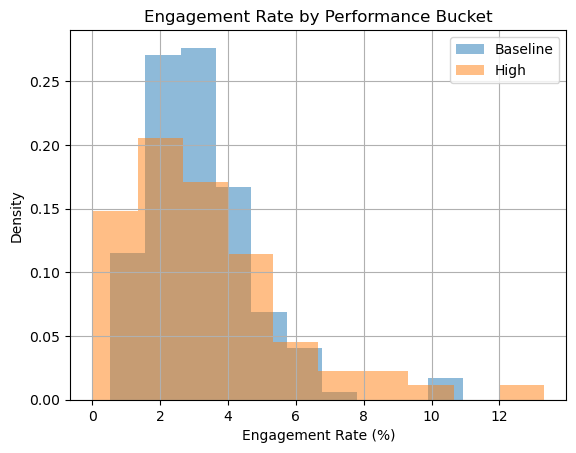

In [9]:
explore_df['engagement_rate_pct'] = explore_df['engagement_rate'] * 100

for label, name in [(0, 'Baseline'), (1, 'High')]:
    explore_df.loc[explore_df['performance_bucket'] == label, 'engagement_rate_pct'].hist(
        alpha=0.5, label=name, density=True
    )

plt.title('Engagement Rate by Performance Bucket')
plt.xlabel('Engagement Rate (%)')
plt.ylabel('Density')
plt.legend()
plt.show()

The engagement-rate distributions for baseline and high-performing Reels overlap substantially, so engagement alone does not clearly separate the groups. High-performing Reels have a longer right tail, which means a greater chance of reaching very high engagement values.

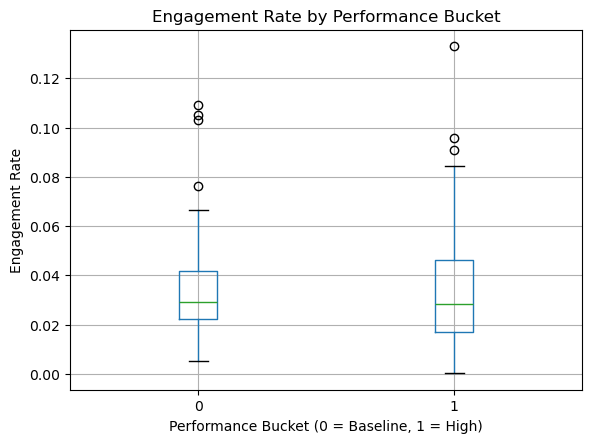

In [10]:
explore_df.boxplot(column='engagement_rate', by='performance_bucket')

plt.title('Engagement Rate by Performance Bucket')
plt.suptitle('')  # removes the automatic subtitle
plt.xlabel('Performance Bucket (0 = Baseline, 1 = High)')
plt.ylabel('Engagement Rate')
plt.show()

Median engagement rates are similar in the two groups, but high-performing Reels show more variability and higher extreme values. Strong performance is associated with engagement outliers more than with consistently higher typical engagement.

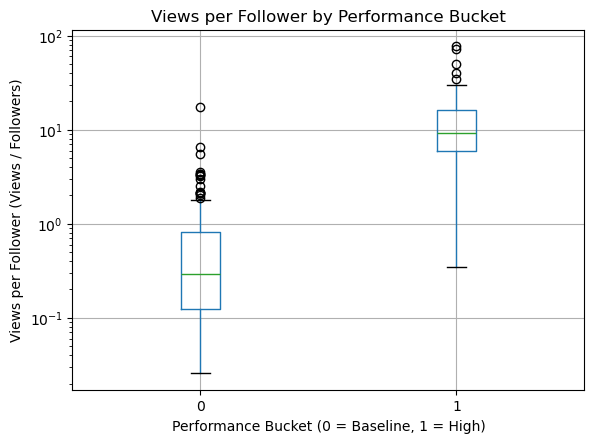

Median views per follower: baseline 0.29, high 9.28 (about 31x higher)


In [11]:
explore_df.boxplot(column='views_per_follower', by='performance_bucket')

plt.title('Views per Follower by Performance Bucket')
plt.suptitle('')
plt.xlabel('Performance Bucket (0 = Baseline, 1 = High)')
plt.ylabel('Views per Follower (Views / Followers)')
plt.yscale('log')
plt.show()

medians = explore_df.groupby('performance_bucket')['views_per_follower'].median()
print(f"Median views per follower: baseline {medians[0]:.2f}, high {medians[1]:.2f} "
      f"(about {medians[1] / medians[0]:.0f}x higher)")

High-performing Reels have a far higher median number of views per follower (see the printed medians), meaning many times greater reach, and the distributions show minimal overlap. The y-axis is logarithmic, so vertical differences are multiplicative rather than additive. Both groups have outliers, but high-performing Reels show more extreme values, indicating occasional viral reach far beyond typical levels.

**Implication:** `views_per_follower` (like views, likes, comments, and engagement rate) describes the *outcome*, so it is not used as a predictor.

### c) Numeric relationships and the age of the Reel

Correlation with performance_bucket:
days_since_posted     0.755
views_per_follower    0.600
views                 0.566
likes                 0.532
comments              0.429
engagement_rate       0.033
total_followers       0.024
Name: performance_bucket, dtype: float64


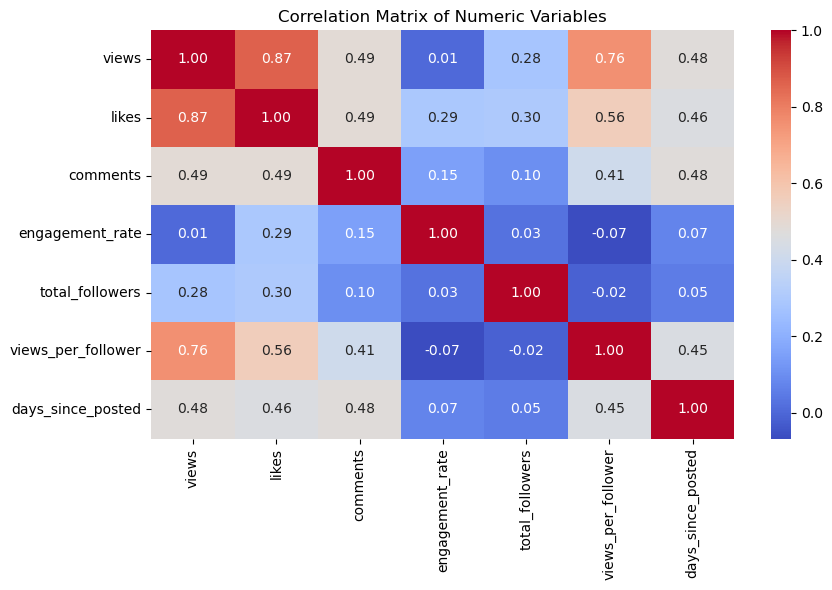

In [12]:
numeric_cols = [
    'views', 'likes', 'comments', 'engagement_rate',
    'total_followers', 'views_per_follower', 'days_since_posted'
]

# Which numeric variables move with the target?
corr_with_target = (
    explore_df[numeric_cols + ['performance_bucket']]
    .corr()['performance_bucket']
    .drop('performance_bucket')
    .sort_values(ascending=False)
    .round(3)
)
print("Correlation with performance_bucket:")
print(corr_with_target)

plt.figure(figsize=(9, 6))
sns.heatmap(explore_df[numeric_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Matrix of Numeric Variables')
plt.tight_layout()
plt.show()

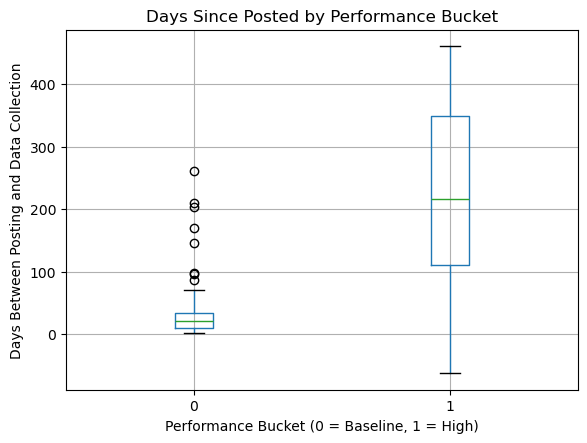

In [13]:
explore_df.boxplot(column='days_since_posted', by='performance_bucket')

plt.title('Days Since Posted by Performance Bucket')
plt.suptitle('')
plt.xlabel('Performance Bucket (0 = Baseline, 1 = High)')
plt.ylabel('Days Between Posting and Data Collection')
plt.show()

Views, likes, and comments are strongly correlated with one another, so they capture overlapping information about engagement volume. A correlation matrix only measures how numeric variables move together, and most predictors in this project are categorical or binary, so the category-level tables and heatmaps below are more informative for the questions of interest.

`days_since_posted` is also strongly associated with the target (see the correlation table above). Older Reels have had longer to accumulate views, so recency is a confounder to keep in mind when interpreting content effects.

### d) Performance rate by content category

For each category, the table shows the number of Reels (`n_reels`) and the share that are high-performing (`high_rate`), compared with the overall rate. Because the rate is calculated within each category, it answers the question of interest: *how likely is a Reel to be high-performing, given its category?*

In [14]:
def rate_by_category(df, col):
    """Number of reels and high-performing rate for each value of a categorical column."""
    return (
        df.groupby(col)['performance_bucket']
        .agg(n_reels='size', high_rate='mean')
        .sort_values('high_rate', ascending=False)
    )

def plot_rate(summary, title, ylabel):
    fig, ax = plt.subplots(figsize=(9, max(4, 0.45 * len(summary))))
    labels = [f"{idx} (n={n})" for idx, n in zip(summary.index, summary['n_reels'])]
    ax.barh(labels, summary['high_rate'])
    ax.axvline(overall_rate, linestyle='--', color='gray', label=f"Overall rate ({overall_rate:.1%})")
    ax.invert_yaxis()  # highest rate at the top
    ax.set_title(title)
    ax.set_xlabel('Share of Reels That Are High-Performing')
    ax.set_ylabel(ylabel)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    ax.legend()
    plt.tight_layout()
    plt.show()

def describe_rates(summary, min_n=15):
    """Print the highest and lowest rates among categories with at least min_n reels."""
    eligible = summary[summary['n_reels'] >= min_n]
    if len(eligible) < 2:
        return
    top, bottom = eligible.iloc[0], eligible.iloc[-1]
    print(f"Highest rate (n >= {min_n}): {eligible.index[0]} at {top['high_rate']:.0%} ({int(top['n_reels'])} reels)")
    print(f"Lowest rate  (n >= {min_n}): {eligible.index[-1]} at {bottom['high_rate']:.0%} ({int(bottom['n_reels'])} reels)")
    small = summary[summary['n_reels'] < min_n]
    if len(small):
        print(f"Categories with fewer than {min_n} reels (treat as tentative): {', '.join(small.index)}")

                     n_reels  high_rate
craft_category                         
fiber_arts                 2      0.500
plants_garden             14      0.429
holiday_seasonal          41      0.366
upcycling                 23      0.348
sculpture_clay            20      0.300
home_decor                83      0.253
paper_cardboard           29      0.207
fine_art_paint             5      0.200
costume_wearables          5      0.200
miniatures_dioramas        9      0.111
sewing_fabric              2      0.000
Highest rate (n >= 15): holiday_seasonal at 37% (41 reels)
Lowest rate  (n >= 15): paper_cardboard at 21% (29 reels)
Categories with fewer than 15 reels (treat as tentative): fiber_arts, plants_garden, fine_art_paint, costume_wearables, miniatures_dioramas, sewing_fabric


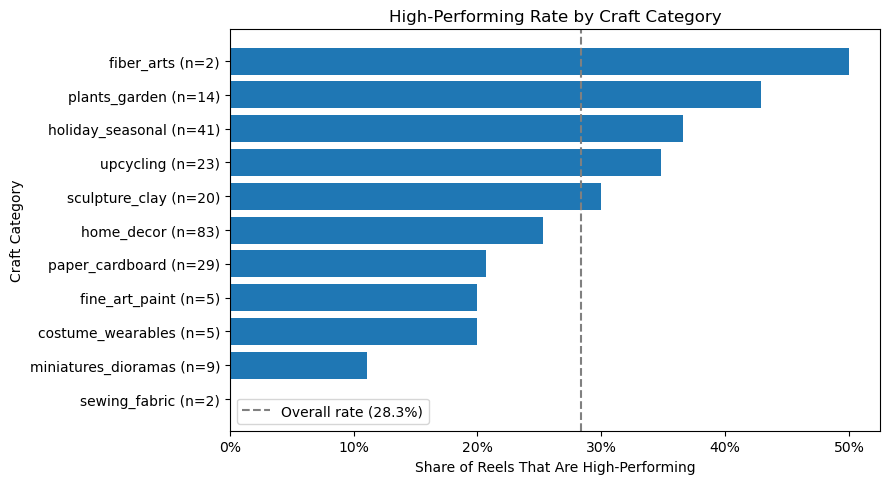

In [15]:
craft_rates = rate_by_category(explore_df, 'craft_category')
print(craft_rates.round(3))
describe_rates(craft_rates)
plot_rate(craft_rates, 'High-Performing Rate by Craft Category', 'Craft Category')

                       n_reels  high_rate
hook_category                            
declarative_authority        4      0.500
curiosity_gap               62      0.323
transformation_tease        34      0.294
direct_value_delivery      113      0.257
pain_point                   8      0.250
relatable_observation       12      0.250
Highest rate (n >= 15): curiosity_gap at 32% (62 reels)
Lowest rate  (n >= 15): direct_value_delivery at 26% (113 reels)
Categories with fewer than 15 reels (treat as tentative): declarative_authority, pain_point, relatable_observation


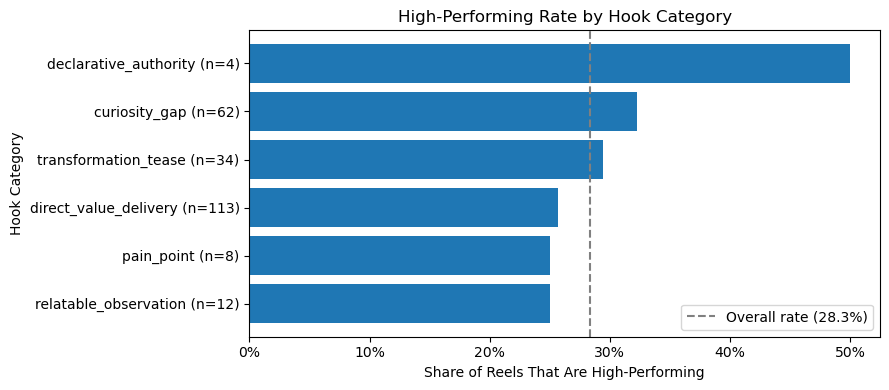

In [16]:
hook_rates = rate_by_category(explore_df, 'hook_category')
print(hook_rates.round(3))
describe_rates(hook_rates)
plot_rate(hook_rates, 'High-Performing Rate by Hook Category', 'Hook Category')

                n_reels  high_rate
reel_structure                    
process             164      0.317
list                 12      0.250
showcase             20      0.200
transformation       31      0.194
narrative             6      0.167
Highest rate (n >= 15): process at 32% (164 reels)
Lowest rate  (n >= 15): transformation at 19% (31 reels)
Categories with fewer than 15 reels (treat as tentative): list, narrative


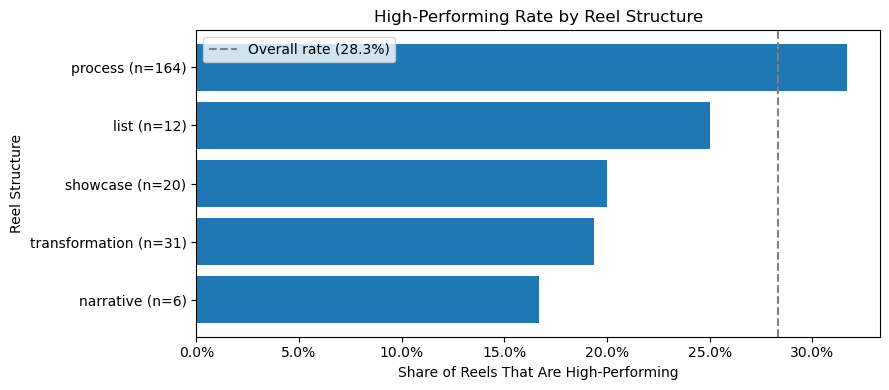

In [17]:
structure_rates = rate_by_category(explore_df, 'reel_structure')
print(structure_rates.round(3))
describe_rates(structure_rates)
plot_rate(structure_rates, 'High-Performing Rate by Reel Structure', 'Reel Structure')

Rates based on a small number of Reels can look extreme by chance, so categories with few Reels should be read as tentative. Compare each category's rate with the overall rate (dashed line) and with its sample size.

### e) Delivery features (binary)

                    high_rate_absent  high_rate_present  n_present  difference
pov_present                    0.263              0.285      214.0       0.022
result_shown_first             0.285              0.280       75.0      -0.005
voice_present                  0.285              0.280       82.0      -0.004
audio_not_required             0.283              0.286       49.0       0.003


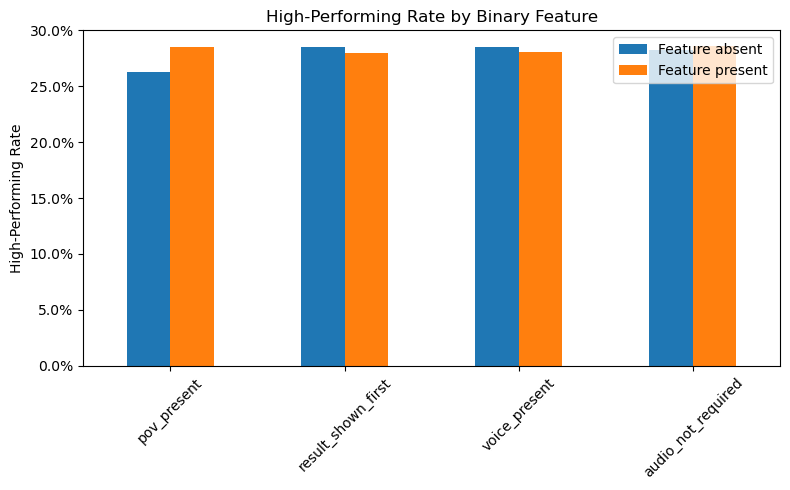

In [18]:
binary_summary = pd.DataFrame({
    col: {
        'high_rate_absent': explore_df.loc[explore_df[col] == 0, 'performance_bucket'].mean(),
        'high_rate_present': explore_df.loc[explore_df[col] == 1, 'performance_bucket'].mean(),
        'n_present': int((explore_df[col] == 1).sum()),
    }
    for col in binary_cols
}).T
binary_summary['difference'] = binary_summary['high_rate_present'] - binary_summary['high_rate_absent']
print(binary_summary.round(3))

ax = binary_summary[['high_rate_absent', 'high_rate_present']].plot(kind='bar', figsize=(8, 5))
ax.set_title('High-Performing Rate by Binary Feature')
ax.set_ylabel('High-Performing Rate')
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.legend(['Feature absent', 'Feature present'])
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

The high-performing rate is nearly the same whether or not each delivery feature is present (compare the two bars for each feature and the `difference` column). No single delivery feature separates high-performing Reels from baseline ones on its own, so any effect of these choices would have to show up in combination with other features or be small. Note that `pov_present` is 1 for the vast majority of Reels, so its "absent" group is very small.

### f) Interactions between features

Single-feature views can hide patterns that appear only in combinations (for example, a hook type that works well only with a certain structure). The heatmaps show the high-performing rate for each pair of categories. Cells with fewer than 8 Reels are left blank because their rates are unreliable.

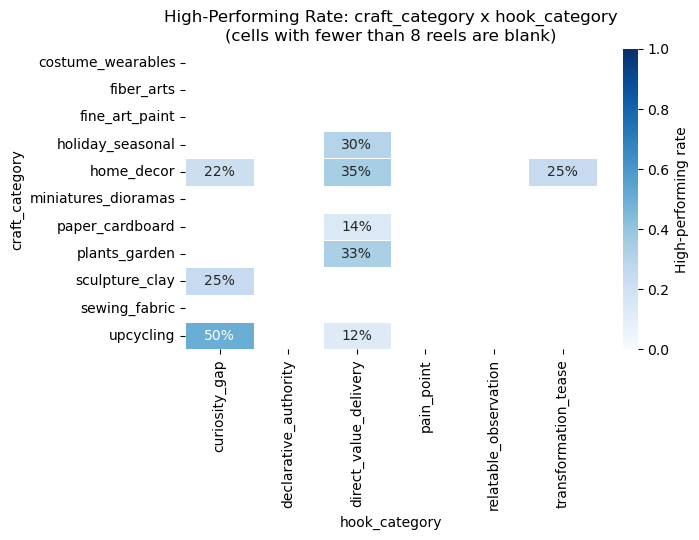

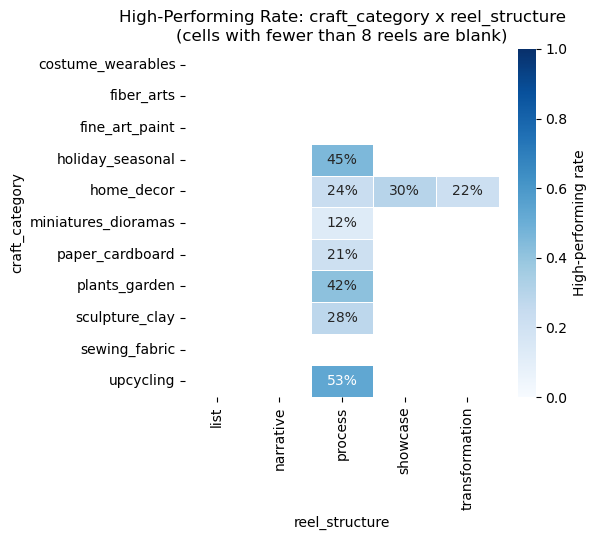

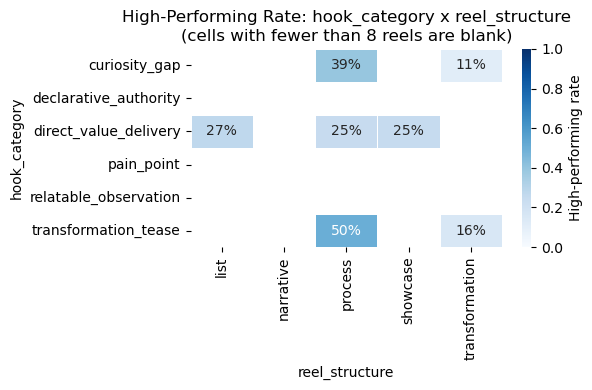

In [19]:
def interaction_heatmap(df, row_col, col_col, min_n=8):
    counts = pd.crosstab(df[row_col], df[col_col])
    rates = pd.crosstab(df[row_col], df[col_col], values=df['performance_bucket'], aggfunc='mean')
    rates = rates.where(counts >= min_n)  # hide cells with too few reels

    plt.figure(figsize=(max(6, 1.2 * rates.shape[1]), max(4, 0.5 * rates.shape[0])))
    sns.heatmap(rates, annot=True, fmt='.0%', cmap='Blues', vmin=0, vmax=1,
                linewidths=0.5, mask=rates.isna(), cbar_kws={'label': 'High-performing rate'})
    plt.title(f'High-Performing Rate: {row_col} x {col_col}\n(cells with fewer than {min_n} reels are blank)')
    plt.tight_layout()
    plt.show()

interaction_heatmap(explore_df, 'craft_category', 'hook_category')
interaction_heatmap(explore_df, 'craft_category', 'reel_structure')
interaction_heatmap(explore_df, 'hook_category', 'reel_structure')

Cells with enough Reels show how the rate varies across category pairs. Compare each cell with the overall rate and treat cells with few Reels cautiously. The pairs that stood out motivated the **interaction features** built in Notebook 2 and tested in the second modeling iteration in Notebook 3.

## 2.5 Summary and next steps for Data Preparation

| Finding | Next Steps |
|---|---|
| About 30% of Reels are high-performing | Use a stratified split and judge models on F1 and recall for the high-performing class |
| Views, likes, comments, engagement rate, and views per follower describe the outcome | Exclude them from the predictors |
| Older Reels are more likely to be high-performing | Keep `days_since_posted` out of the content predictors and discuss it as a limitation |
| Counts are text with `K`/`M`, dates are in mixed formats, labels vary in case, delivery variables are `Y`/`N` | Standardize and convert in Notebook 2 |
| Several categories contain very few Reels | Drop extremely rare indicator columns before modeling |
| Some Reels appear twice with opposite labels, and one hook value is a placeholder | Resolve the conflicting duplicates and remove the placeholder row |
| Delivery features show almost no difference in rate on their own | Keep them as predictors, but expect any signal to be small or to come from combinations |
| Some category pairs may behave differently from their single-feature rates | Construct interaction features and test whether they help |